## 1. Imports

In [108]:
# ============================================================
# 05c LSTM Autoencoder — All 10 voltage-random splits
# Same complex LSTM AE logic as original Notebook 05
# ============================================================

from pathlib import Path
import gc
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

# ============================================================
# Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ============================================================
# Device
# ============================================================

if torch.backends.mps.is_available():
    device = torch.device("mps")
    torch.mps.manual_seed(SEED)
elif torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
else:
    device = torch.device("cpu")

print("Using device:", device)

# ============================================================
# Paths
# ============================================================

BASE_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")

DATA_VERSION = "v3_voltage_random10_interpolated"

INPUT_ROOT = BASE_DIR / f"model_ready_no_dr_{DATA_VERSION}"

EXPERIMENT_NAME = f"lstm_autoencoder_{DATA_VERSION}_old_complex_logic"

MASTER_OUTPUT_DIR = BASE_DIR / "model_outputs" / EXPERIMENT_NAME

MASTER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Input root :", INPUT_ROOT)
print("Output root:", MASTER_OUTPUT_DIR)

# ============================================================
# All 10 random splits
# ============================================================

SPLIT_SEEDS = [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]

ALL_SPLITS = [
    f"split_{str(i + 1).zfill(2)}_seed_{seed}"
    for i, seed in enumerate(SPLIT_SEEDS)
]

print("\nSplits to run:")
for split_name in ALL_SPLITS:
    print(" ", split_name)

# ============================================================
# Same sequence settings as original LSTM AE
# ============================================================

SEQ_LEN       = 100   # 100 rows = 10 seconds at 10 Hz
STRIDE_TRAIN  = 20    # 2-second stride during training
STRIDE_SCORE  = 10    # 1-second stride during scoring
BATCH_SIZE    = 64

EPOCHS        = 200
PATIENCE      = 15
MAX_GRAD_NORM = 1.0
MIN_DELTA     = 1e-5

FORCE_RERUN = False   # keep False to avoid overwriting completed split outputs

print("\nTraining settings loaded.")

Using device: mps
Input root : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr_v3_voltage_random10_interpolated
Output root: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic

Splits to run:
  split_01_seed_11
  split_02_seed_22
  split_03_seed_33
  split_04_seed_44
  split_05_seed_55
  split_06_seed_66
  split_07_seed_77
  split_08_seed_88
  split_09_seed_99
  split_10_seed_111

Training settings loaded.


In [109]:
# ============================================================
# Feature selection
# Original final 11 non-DR features + 2 voltage-per-cell features
# ============================================================

target_col = "target_energy_next_60s_wh"

feature_cols = [
    "battery_status__cell_count",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__discharged_mah",
    "battery_status__remaining",
    "battery_status__scale",
    "battery_status__voltage_filtered_v",
    "battery_status__voltage_v",
    "cumulative_energy_wh",
    "power_w",
    "time_s",

    # New voltage-quality physical features
    "voltage_per_cell",
    "voltage_filtered_per_cell"
]

print("Number of LSTM AE features:", len(feature_cols))
print(feature_cols)

assert len(feature_cols) == 13
assert "energy_increment_wh" not in feature_cols
assert "battery_status__voltage_cell_v[0]" not in feature_cols
assert "voltage_per_cell_suspicious" not in feature_cols

Number of LSTM AE features: 13
['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'voltage_per_cell', 'voltage_filtered_per_cell']


In [110]:
# ============================================================
# Load split files
# ============================================================

def load_split_files(input_dir, split_name):
    train_path = input_dir / f"train_no_dr_scaled_{DATA_VERSION}_{split_name}.parquet"
    val_path   = input_dir / f"val_no_dr_scaled_{DATA_VERSION}_{split_name}.parquet"
    test_path  = input_dir / f"test_no_dr_scaled_{DATA_VERSION}_{split_name}.parquet"

    for name, path in [
        ("train", train_path),
        ("validation", val_path),
        ("test", test_path)
    ]:
        if not path.exists():
            raise FileNotFoundError(
                f"Missing {name} file for {split_name}:\n{path}"
            )

    train_df = pd.read_parquet(train_path)
    val_df   = pd.read_parquet(val_path)
    test_df  = pd.read_parquet(test_path)

    print("Loaded files:")
    print("Train:", train_path.name)
    print("Val  :", val_path.name)
    print("Test :", test_path.name)

    return train_df, val_df, test_df


# ============================================================
# Prepare sorted dataframe
# ============================================================

def prepare_sorted_df(df):
    df = df.copy()
    df["_original_order"] = np.arange(len(df))
    df["log_id"] = df["log_id"].astype(str)

    return (
        df.sort_values(["log_id", "time_s"])
        .reset_index(drop=True)
    )


# ============================================================
# Validate data before training
# ============================================================

def validate_data(train_df, val_df, test_df, split_name):
    required_cols = (
        ["log_id", "dataset_label", target_col, "voltage_per_cell_suspicious"]
        + feature_cols
    )

    for split_label, df in [
        ("Train", train_df),
        ("Validation", val_df),
        ("Test", test_df)
    ]:
        missing_cols = [col for col in required_cols if col not in df.columns]

        if missing_cols:
            raise ValueError(
                f"{split_name} | {split_label}: missing columns: {missing_cols}"
            )

        nan_count = int(df[feature_cols].isna().sum().sum())

        if nan_count > 0:
            bad_cols = df[feature_cols].columns[
                df[feature_cols].isna().any()
            ].tolist()

            raise ValueError(
                f"{split_name} | {split_label}: {nan_count} NaN values "
                f"found in feature columns: {bad_cols}"
            )

    print("Data validation passed.")


# ============================================================
# Window builder
# Training can use clean normal windows only.
# Scoring uses all windows.
# ============================================================

def build_window_starts(
    df_sorted,
    seq_len,
    stride,
    normal_only=False,
    clean_only=False
):
    window_starts = []

    for log_id, group in df_sorted.groupby("log_id", sort=False):
        indices = group.index.to_numpy()
        n = len(group)

        if n < seq_len:
            continue

        for local_start in range(0, n - seq_len + 1, stride):
            local_end = local_start + seq_len
            window_indices = indices[local_start:local_end]
            window_df = df_sorted.loc[window_indices]

            if normal_only:
                if not (window_df["dataset_label"] == "normal").all():
                    continue

            if clean_only:
                if not (window_df["voltage_per_cell_suspicious"] == 0).all():
                    continue

            window_starts.append(window_indices[0])

    return np.array(window_starts, dtype=np.int64)


# ============================================================
# Dataset classes
# ============================================================

class UAVTrainSequenceDataset(Dataset):
    def __init__(self, data_array, window_starts, seq_len):
        self.data_array = data_array
        self.window_starts = window_starts
        self.seq_len = seq_len

    def __len__(self):
        return len(self.window_starts)

    def __getitem__(self, idx):
        start = self.window_starts[idx]
        end = start + self.seq_len
        sequence = self.data_array[start:end]

        return torch.tensor(sequence, dtype=torch.float32)


class UAVScoringSequenceDataset(Dataset):
    def __init__(self, data_array, window_starts, seq_len):
        self.data_array = data_array
        self.window_starts = window_starts
        self.seq_len = seq_len

    def __len__(self):
        return len(self.window_starts)

    def __getitem__(self, idx):
        start = self.window_starts[idx]
        end = start + self.seq_len
        sequence = self.data_array[start:end]

        return torch.tensor(sequence, dtype=torch.float32), start


# ============================================================
# Same complex LSTM Autoencoder as original Notebook 05
# Encoder LSTM → latent → decoder input + h0 + c0 → Decoder LSTM
# ============================================================

class LSTMAutoencoder(nn.Module):
    def __init__(self, input_size, hidden_size=64, latent_size=32, num_layers=1):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size
        self.latent_size = latent_size
        self.num_layers = num_layers

        self.encoder_lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.encoder_fc = nn.Linear(hidden_size, latent_size)

        self.decoder_input_fc = nn.Linear(latent_size, hidden_size)
        self.decoder_h0_fc = nn.Linear(latent_size, hidden_size * num_layers)
        self.decoder_c0_fc = nn.Linear(latent_size, hidden_size * num_layers)

        self.decoder_lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.output_layer = nn.Linear(hidden_size, input_size)

    def forward(self, x):
        batch_size, seq_len, _ = x.shape

        _, (hidden, _) = self.encoder_lstm(x)

        hidden_last = hidden[-1]
        latent = self.encoder_fc(hidden_last)

        decoder_input_step = self.decoder_input_fc(latent)
        decoder_input = decoder_input_step.unsqueeze(1).repeat(1, seq_len, 1)

        h0 = self.decoder_h0_fc(latent)
        h0 = h0.view(batch_size, self.num_layers, self.hidden_size)
        h0 = h0.permute(1, 0, 2).contiguous()

        c0 = self.decoder_c0_fc(latent)
        c0 = c0.view(batch_size, self.num_layers, self.hidden_size)
        c0 = c0.permute(1, 0, 2).contiguous()

        decoder_output, _ = self.decoder_lstm(decoder_input, (h0, c0))
        reconstructed = self.output_layer(decoder_output)

        return reconstructed

In [111]:
# ============================================================
# Score dataframe with trained LSTM Autoencoder
# ============================================================

def score_dataframe_with_autoencoder(
    df_sorted,
    feature_cols,
    seq_len,
    stride,
    model_to_score,
    batch_size=64,
    device=device
):
    model_to_score.eval()

    X_array = df_sorted[feature_cols].to_numpy(dtype=np.float32)

    window_starts = build_window_starts(
        df_sorted,
        seq_len=seq_len,
        stride=stride,
        normal_only=False,
        clean_only=False
    )

    print(f"  Scoring windows: {len(window_starts):,}")

    dataset = UAVScoringSequenceDataset(
        data_array=X_array,
        window_starts=window_starts,
        seq_len=seq_len
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        drop_last=False
    )

    score_sum = np.zeros(len(df_sorted), dtype=np.float64)
    score_count = np.zeros(len(df_sorted), dtype=np.float64)

    with torch.no_grad():
        for batch_x, batch_starts in loader:
            batch_x = batch_x.to(device)

            reconstructed = model_to_score(batch_x)

            step_errors = ((batch_x - reconstructed) ** 2).mean(dim=2)
            step_errors = step_errors.cpu().numpy()
            batch_starts = batch_starts.numpy()

            for i, start in enumerate(batch_starts):
                end = start + seq_len
                score_sum[start:end] += step_errors[i]
                score_count[start:end] += 1

    anomaly_score = np.where(score_count > 0, score_sum / score_count, np.nan)

    scored_df = df_sorted.copy()
    scored_df["anomaly_score"] = anomaly_score

    uncovered = int(scored_df["anomaly_score"].isna().sum())

    if uncovered > 0:
        scored_df["anomaly_score"] = (
            scored_df.groupby("log_id")["anomaly_score"]
            .transform(lambda s: s.ffill().bfill())
        )

    still_missing = int(scored_df["anomaly_score"].isna().sum())

    if still_missing > 0:
        normal_median = scored_df.loc[
            scored_df["dataset_label"] == "normal",
            "anomaly_score"
        ].median()

        if pd.notna(normal_median):
            fallback_value = normal_median
        else:
            fallback_value = scored_df["anomaly_score"].median()

        scored_df["anomaly_score"] = scored_df["anomaly_score"].fillna(
            fallback_value
        )

    return scored_df


# ============================================================
# Restore original order and save
# ============================================================

def restore_and_save(scored_df, save_path):
    output_df = (
        scored_df.sort_values("_original_order")
        .drop(columns=["_original_order"])
        .reset_index(drop=True)
    )

    output_df.to_csv(save_path, index=False)

    print("Saved:", save_path)
    print("Shape:", output_df.shape)
    print("Missing anomaly_score:", output_df["anomaly_score"].isna().sum())

    return output_df


# ============================================================
# Row-level summary
# ============================================================

def create_row_summary(df, split_name, data_split):
    records = []

    for label in ["normal", "abnormal"]:
        subset = df[df["dataset_label"] == label]

        if len(subset) == 0:
            continue

        records.append({
            "split": split_name,
            "data_split": data_split,
            "dataset_label": label,
            "n_rows": len(subset),
            "mean_score": subset["anomaly_score"].mean(),
            "std_score": subset["anomaly_score"].std(),
            "median_score": subset["anomaly_score"].median(),
            "p95_score": subset["anomaly_score"].quantile(0.95),
            "flagged_pct": subset["anomaly_flag"].mean() * 100,
            "mean_power_w": subset["power_w"].mean(),
            "mean_current": subset["battery_status__current_a"].mean(),
            "mean_voltage": subset["battery_status__voltage_filtered_v"].mean(),
            "mean_remaining": subset["battery_status__remaining"].mean(),
            "mean_voltage_per_cell": subset["voltage_per_cell"].mean(),
            "suspicious_pct": subset["voltage_per_cell_suspicious"].mean() * 100
        })

    return pd.DataFrame(records)


# ============================================================
# Flight-level summary
# ============================================================

def create_flight_summary(df, split_name, data_split, threshold):
    flight_summary = (
        df.groupby(["log_id", "dataset_label"])
        .agg(
            mean_anomaly_score=("anomaly_score", "mean"),
            max_anomaly_score=("anomaly_score", "max"),
            std_anomaly_score=("anomaly_score", "std"),
            flagged_percentage=("anomaly_flag", "mean"),
            rows=("anomaly_score", "size"),

            mean_power_w=("power_w", "mean"),
            mean_current=("battery_status__current_a", "mean"),
            mean_voltage=("battery_status__voltage_filtered_v", "mean"),
            mean_remaining=("battery_status__remaining", "mean"),
            mean_voltage_per_cell=("voltage_per_cell", "mean"),
            mean_voltage_filtered_per_cell=("voltage_filtered_per_cell", "mean"),
            suspicious_percentage=("voltage_per_cell_suspicious", "mean")
        )
        .reset_index()
    )

    flight_summary["flagged_percentage"] *= 100
    flight_summary["suspicious_percentage"] *= 100

    flight_summary["split"] = split_name
    flight_summary["data_split"] = data_split
    flight_summary["threshold"] = threshold

    return flight_summary


# ============================================================
# Detection metrics
# ============================================================

def compute_flight_metrics(flight_summary, split_name, data_split):
    flight_eval = flight_summary.copy()

    flight_eval["binary_label"] = (
        flight_eval["dataset_label"] == "abnormal"
    ).astype(int)

    n_normal = int((flight_eval["binary_label"] == 0).sum())
    n_abnormal = int((flight_eval["binary_label"] == 1).sum())

    if flight_eval["binary_label"].nunique() == 2:
        auroc = roc_auc_score(
            flight_eval["binary_label"],
            flight_eval["mean_anomaly_score"]
        )

        auprc = average_precision_score(
            flight_eval["binary_label"],
            flight_eval["mean_anomaly_score"]
        )

        baseline_auprc = flight_eval["binary_label"].mean()
    else:
        auroc = np.nan
        auprc = np.nan
        baseline_auprc = np.nan

    normal_flights = flight_summary[flight_summary["dataset_label"] == "normal"]
    abnormal_flights = flight_summary[flight_summary["dataset_label"] == "abnormal"]

    normal_mean = normal_flights["mean_anomaly_score"].mean()
    abnormal_mean = abnormal_flights["mean_anomaly_score"].mean()

    separation_ratio = (
        abnormal_mean / normal_mean
        if pd.notna(abnormal_mean) and normal_mean > 0
        else np.nan
    )

    return {
        "split": split_name,
        "data_split": data_split,
        "n_normal_flights": n_normal,
        "n_abnormal_flights": n_abnormal,
        "mean_flight_score_normal": normal_mean,
        "mean_flight_score_abnormal": abnormal_mean,
        "separation_ratio": separation_ratio,
        "mean_flagged_pct_normal": normal_flights["flagged_percentage"].mean(),
        "mean_flagged_pct_abnormal": abnormal_flights["flagged_percentage"].mean(),
        "flight_auroc": auroc,
        "flight_auprc": auprc,
        "baseline_auprc": baseline_auprc
    }


# ============================================================
# Plots per split
# ============================================================

def save_training_curve(train_losses, val_losses, plot_dir, split_name):
    plt.figure(figsize=(8, 5))

    plt.plot(range(1, len(train_losses) + 1), train_losses, label="Train loss")
    plt.plot(range(1, len(val_losses) + 1), val_losses, label="Validation loss")

    plt.xlabel("Epoch")
    plt.ylabel("Reconstruction loss")
    plt.title(f"LSTM AE Training Curve — {split_name}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    save_path = plot_dir / f"training_curve_{DATA_VERSION}_{split_name}.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close()

    print("Saved plot:", save_path)


def save_distribution_plot(train_out, val_out, test_out, threshold, plot_dir, split_name):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (data_split, df) in zip(
        axes,
        [("Train", train_out), ("Validation", val_out), ("Test", test_out)]
    ):
        for label, color in [("normal", "steelblue"), ("abnormal", "tomato")]:
            subset = df[df["dataset_label"] == label]

            if len(subset) > 0:
                ax.hist(
                    subset["anomaly_score"],
                    bins=60,
                    alpha=0.6,
                    density=True,
                    label=f"{label} (n={len(subset):,})",
                    color=color
                )

        ax.axvline(
            threshold,
            color="black",
            linestyle="--",
            linewidth=1.2,
            label=f"Threshold={threshold:.4f}"
        )

        ax.set_title(data_split)
        ax.set_xlabel("Anomaly score")
        ax.set_ylabel("Density")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    plt.suptitle(f"Anomaly Score Distribution — {split_name}", fontsize=13, y=1.02)
    plt.tight_layout()

    save_path = plot_dir / f"anomaly_score_distribution_{DATA_VERSION}_{split_name}.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close()

    print("Saved plot:", save_path)


def save_flight_bar_plot(flight_summary, plot_dir, split_name, data_split):
    plot_df = (
        flight_summary
        .sort_values("mean_anomaly_score", ascending=False)
        .reset_index(drop=True)
    )

    colors = plot_df["dataset_label"].map({
        "normal": "steelblue",
        "abnormal": "tomato"
    })

    plt.figure(figsize=(14, 5))

    plt.bar(range(len(plot_df)), plot_df["mean_anomaly_score"], color=colors)

    plt.xlabel("Flight ranked by mean anomaly score")
    plt.ylabel("Mean anomaly score")
    plt.title(f"Per-Flight Mean Anomaly Score — {split_name} — {data_split}")
    plt.grid(True, alpha=0.3, axis="y")

    from matplotlib.patches import Patch
    legend_items = [
        Patch(facecolor="steelblue", label="normal"),
        Patch(facecolor="tomato", label="abnormal")
    ]

    plt.legend(handles=legend_items)
    plt.tight_layout()

    save_path = plot_dir / f"per_flight_score_{data_split.lower()}_{DATA_VERSION}_{split_name}.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close()

    print("Saved plot:", save_path)


def save_roc_plot(flight_summary, plot_dir, split_name, data_split):
    flight_eval = flight_summary.copy()

    flight_eval["binary_label"] = (
        flight_eval["dataset_label"] == "abnormal"
    ).astype(int)

    if flight_eval["binary_label"].nunique() < 2:
        print(f"Skipping ROC plot for {split_name} {data_split}: only one class.")
        return

    fpr, tpr, _ = roc_curve(
        flight_eval["binary_label"],
        flight_eval["mean_anomaly_score"]
    )

    auroc = roc_auc_score(
        flight_eval["binary_label"],
        flight_eval["mean_anomaly_score"]
    )

    plt.figure(figsize=(6, 5))

    plt.plot(fpr, tpr, label=f"LSTM AE AUROC={auroc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")

    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"ROC Curve — {split_name} — {data_split}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    save_path = plot_dir / f"roc_curve_{data_split.lower()}_{DATA_VERSION}_{split_name}.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close()

    print("Saved plot:", save_path)

In [112]:
# ============================================================
# MAIN LOOP — Train and score all 10 splits separately
# ============================================================

ALL_METRICS = []
ALL_ROW_SUMMARIES = []
ALL_FLIGHT_SUMMARIES = []

for SPLIT_NAME in ALL_SPLITS:

    print("\n" + "="*100)
    print(f"STARTING SPLIT: {SPLIT_NAME}")
    print("="*100)

    INPUT_DIR = INPUT_ROOT / SPLIT_NAME

    OUTPUT_DIR = MASTER_OUTPUT_DIR / SPLIT_NAME
    PLOT_DIR = OUTPUT_DIR / "plots"

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    PLOT_DIR.mkdir(parents=True, exist_ok=True)

    model_path = OUTPUT_DIR / "best_lstm_autoencoder.pt"

    train_save_path = OUTPUT_DIR / f"train_no_dr_with_lstm_anomaly_score_{DATA_VERSION}_{SPLIT_NAME}.csv"
    val_save_path   = OUTPUT_DIR / f"val_no_dr_with_lstm_anomaly_score_{DATA_VERSION}_{SPLIT_NAME}.csv"
    test_save_path  = OUTPUT_DIR / f"test_no_dr_with_lstm_anomaly_score_{DATA_VERSION}_{SPLIT_NAME}.csv"

    train_flight_summary_path = OUTPUT_DIR / f"flight_summary_train_{DATA_VERSION}_{SPLIT_NAME}.csv"
    val_flight_summary_path   = OUTPUT_DIR / f"flight_summary_validation_{DATA_VERSION}_{SPLIT_NAME}.csv"
    test_flight_summary_path  = OUTPUT_DIR / f"flight_summary_test_{DATA_VERSION}_{SPLIT_NAME}.csv"

    row_summary_path = OUTPUT_DIR / f"row_summary_{DATA_VERSION}_{SPLIT_NAME}.csv"
    metrics_path = OUTPUT_DIR / f"metrics_{DATA_VERSION}_{SPLIT_NAME}.csv"
    history_path = OUTPUT_DIR / f"training_history_{DATA_VERSION}_{SPLIT_NAME}.csv"

    completed = (
        train_save_path.exists()
        and val_save_path.exists()
        and test_save_path.exists()
        and test_flight_summary_path.exists()
    )

    if completed and not FORCE_RERUN:
        print("Split already completed. Loading saved outputs.")

        train_out = pd.read_csv(train_save_path, low_memory=False)
        val_out   = pd.read_csv(val_save_path, low_memory=False)
        test_out  = pd.read_csv(test_save_path, low_memory=False)

        train_flight_summary = pd.read_csv(train_flight_summary_path, low_memory=False)
        val_flight_summary   = pd.read_csv(val_flight_summary_path, low_memory=False)
        test_flight_summary  = pd.read_csv(test_flight_summary_path, low_memory=False)

        threshold = float(test_flight_summary["threshold"].iloc[0])

    else:
        train_df, val_df, test_df = load_split_files(INPUT_DIR, SPLIT_NAME)

        print("Train:", train_df.shape)
        print("Val  :", val_df.shape)
        print("Test :", test_df.shape)

        validate_data(train_df, val_df, test_df, SPLIT_NAME)

        # ----------------------------------------------------
        # Sort
        # ----------------------------------------------------

        train_sorted = prepare_sorted_df(train_df)
        val_sorted   = prepare_sorted_df(val_df)
        test_sorted  = prepare_sorted_df(test_df)

        # ----------------------------------------------------
        # Build training windows
        # Training uses clean normal windows only.
        # ----------------------------------------------------

        train_window_starts = build_window_starts(
            train_sorted,
            seq_len=SEQ_LEN,
            stride=STRIDE_TRAIN,
            normal_only=True,
            clean_only=True
        )

        val_ae_window_starts = build_window_starts(
            val_sorted,
            seq_len=SEQ_LEN,
            stride=STRIDE_TRAIN,
            normal_only=True,
            clean_only=True
        )

        print(f"Clean normal training windows: {len(train_window_starts):,}")
        print(f"Clean normal validation windows: {len(val_ae_window_starts):,}")

        if len(train_window_starts) == 0:
            print(f"Skipping {SPLIT_NAME}: no clean normal training windows.")
            continue

        if len(val_ae_window_starts) == 0:
            print(f"Skipping {SPLIT_NAME}: no clean normal validation windows.")
            continue

        # ----------------------------------------------------
        # DataLoaders
        # ----------------------------------------------------

        X_train_array = train_sorted[feature_cols].to_numpy(dtype=np.float32)
        X_val_array   = val_sorted[feature_cols].to_numpy(dtype=np.float32)

        train_dataset = UAVTrainSequenceDataset(
            data_array=X_train_array,
            window_starts=train_window_starts,
            seq_len=SEQ_LEN
        )

        val_ae_dataset = UAVTrainSequenceDataset(
            data_array=X_val_array,
            window_starts=val_ae_window_starts,
            seq_len=SEQ_LEN
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            drop_last=False
        )

        val_ae_loader = DataLoader(
            val_ae_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            drop_last=False
        )

        print("Train batches:", len(train_loader))
        print("Validation batches:", len(val_ae_loader))

        # ----------------------------------------------------
        # Model
        # ----------------------------------------------------

        model = LSTMAutoencoder(
            input_size=len(feature_cols),
            hidden_size=64,
            latent_size=32,
            num_layers=1
        ).to(device)

        criterion = nn.MSELoss()
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

        total_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

        print(model)
        print(f"Total trainable parameters: {total_params:,}")

        # ----------------------------------------------------
        # Training loop
        # ----------------------------------------------------

        best_val_loss = np.inf
        patience_counter = 0

        train_losses = []
        val_losses = []

        for epoch in range(1, EPOCHS + 1):

            model.train()
            epoch_train_losses = []

            for batch_x in train_loader:
                batch_x = batch_x.to(device)

                optimizer.zero_grad()

                reconstructed = model(batch_x)
                loss = criterion(reconstructed, batch_x)

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=MAX_GRAD_NORM
                )

                optimizer.step()

                epoch_train_losses.append(loss.item())

            epoch_train_loss = float(np.mean(epoch_train_losses))
            train_losses.append(epoch_train_loss)

            model.eval()
            epoch_val_losses = []

            with torch.no_grad():
                for batch_x in val_ae_loader:
                    batch_x = batch_x.to(device)

                    reconstructed = model(batch_x)
                    val_loss = criterion(reconstructed, batch_x)

                    epoch_val_losses.append(val_loss.item())

            epoch_val_loss = float(np.mean(epoch_val_losses))
            val_losses.append(epoch_val_loss)

            gap = epoch_val_loss - epoch_train_loss

            print(
                f"Epoch {epoch:03d} | "
                f"Train: {epoch_train_loss:.6f} | "
                f"Val: {epoch_val_loss:.6f} | "
                f"Gap: {gap:+.6f}"
            )

            if epoch_val_loss < best_val_loss - MIN_DELTA:
                best_val_loss = epoch_val_loss
                patience_counter = 0

                torch.save(model.state_dict(), model_path)

                print(f"  --> Best model saved (val loss: {best_val_loss:.6f})")
            else:
                patience_counter += 1

            if patience_counter >= PATIENCE:
                print(f"Early stopping at epoch {epoch} (patience={PATIENCE}).")
                break

        print("\nTraining completed.")
        print(f"Best validation loss : {best_val_loss:.6f}")
        print(f"Final train/val gap  : {val_losses[-1] - train_losses[-1]:+.6f}")

        # Save history
        history_df = pd.DataFrame({
            "epoch": range(1, len(train_losses) + 1),
            "train_loss": train_losses,
            "val_loss": val_losses
        })

        history_df.to_csv(history_path, index=False)

        save_training_curve(train_losses, val_losses, PLOT_DIR, SPLIT_NAME)

        # ----------------------------------------------------
        # Load best model
        # ----------------------------------------------------

        assert model_path.exists(), f"Best model not saved: {model_path}"

        model.load_state_dict(
            torch.load(
                model_path,
                map_location=device,
                weights_only=True
            )
        )

        model.to(device)
        model.eval()

        print("Best model loaded.")

        # ----------------------------------------------------
        # Score train / validation / test
        # ----------------------------------------------------

        print("\nScoring train set...")
        train_scored = score_dataframe_with_autoencoder(
            train_sorted,
            feature_cols,
            seq_len=SEQ_LEN,
            stride=STRIDE_SCORE,
            model_to_score=model,
            batch_size=BATCH_SIZE,
            device=device
        )

        print("\nScoring validation set...")
        val_scored = score_dataframe_with_autoencoder(
            val_sorted,
            feature_cols,
            seq_len=SEQ_LEN,
            stride=STRIDE_SCORE,
            model_to_score=model,
            batch_size=BATCH_SIZE,
            device=device
        )

        print("\nScoring test set...")
        test_scored = score_dataframe_with_autoencoder(
            test_sorted,
            feature_cols,
            seq_len=SEQ_LEN,
            stride=STRIDE_SCORE,
            model_to_score=model,
            batch_size=BATCH_SIZE,
            device=device
        )

        # ----------------------------------------------------
        # Threshold from normal training rows only
        # ----------------------------------------------------

        train_normal_scores = train_scored.loc[
            train_scored["dataset_label"] == "normal",
            "anomaly_score"
        ].dropna()

        assert len(train_normal_scores) > 0

        threshold = float(np.percentile(train_normal_scores, 95))

        print(f"\nAnomaly threshold: {threshold:.6f}")
        print(f"Threshold computed from {len(train_normal_scores):,} normal training rows.")

        for df in [train_scored, val_scored, test_scored]:
            df["anomaly_flag"] = (
                df["anomaly_score"] > threshold
            ).astype(int)

        for split_label, df in [
            ("Train", train_scored),
            ("Validation", val_scored),
            ("Test", test_scored)
        ]:
            print(f"\n{split_label} flagged percentage by label:")
            print(
                (df.groupby("dataset_label")["anomaly_flag"].mean() * 100)
                .round(2)
                .to_string()
            )

        # ----------------------------------------------------
        # Save scored datasets
        # ----------------------------------------------------

        train_out = restore_and_save(train_scored, train_save_path)
        val_out   = restore_and_save(val_scored, val_save_path)
        test_out  = restore_and_save(test_scored, test_save_path)

        # ----------------------------------------------------
        # Create and save summaries
        # ----------------------------------------------------

        train_flight_summary = create_flight_summary(
            train_out,
            SPLIT_NAME,
            "Train",
            threshold
        )

        val_flight_summary = create_flight_summary(
            val_out,
            SPLIT_NAME,
            "Validation",
            threshold
        )

        test_flight_summary = create_flight_summary(
            test_out,
            SPLIT_NAME,
            "Test",
            threshold
        )

        train_flight_summary.to_csv(train_flight_summary_path, index=False)
        val_flight_summary.to_csv(val_flight_summary_path, index=False)
        test_flight_summary.to_csv(test_flight_summary_path, index=False)

        row_summary = pd.concat([
            create_row_summary(train_out, SPLIT_NAME, "Train"),
            create_row_summary(val_out, SPLIT_NAME, "Validation"),
            create_row_summary(test_out, SPLIT_NAME, "Test")
        ], ignore_index=True)

        row_summary.to_csv(row_summary_path, index=False)

        # ----------------------------------------------------
        # Save plots like original notebook
        # ----------------------------------------------------

        save_distribution_plot(train_out, val_out, test_out, threshold, PLOT_DIR, SPLIT_NAME)

        save_flight_bar_plot(val_flight_summary, PLOT_DIR, SPLIT_NAME, "Validation")
        save_flight_bar_plot(test_flight_summary, PLOT_DIR, SPLIT_NAME, "Test")

        save_roc_plot(val_flight_summary, PLOT_DIR, SPLIT_NAME, "Validation")
        save_roc_plot(test_flight_summary, PLOT_DIR, SPLIT_NAME, "Test")

        # ----------------------------------------------------
        # Free memory before next split
        # ----------------------------------------------------

        del model
        del train_df, val_df, test_df
        del train_sorted, val_sorted, test_sorted
        del train_scored, val_scored, test_scored

        gc.collect()

        if device.type == "mps":
            torch.mps.empty_cache()
        elif device.type == "cuda":
            torch.cuda.empty_cache()

    # ========================================================
    # Metrics for this split
    # ========================================================

    split_metrics = []

    for data_split, flight_summary in [
        ("Train", train_flight_summary),
        ("Validation", val_flight_summary),
        ("Test", test_flight_summary)
    ]:
        metrics = compute_flight_metrics(
            flight_summary,
            SPLIT_NAME,
            data_split
        )

        metrics["threshold"] = threshold
        split_metrics.append(metrics)

    split_metrics_df = pd.DataFrame(split_metrics)
    split_metrics_df.to_csv(metrics_path, index=False)

    ALL_METRICS.append(split_metrics_df)

    ALL_ROW_SUMMARIES.append(
        pd.read_csv(row_summary_path, low_memory=False)
    )

    ALL_FLIGHT_SUMMARIES.append(train_flight_summary)
    ALL_FLIGHT_SUMMARIES.append(val_flight_summary)
    ALL_FLIGHT_SUMMARIES.append(test_flight_summary)

    print("\nSplit metrics:")
    display(split_metrics_df)

    test_row = split_metrics_df[split_metrics_df["data_split"] == "Test"].iloc[0]

    print(
        f"\nFINISHED {SPLIT_NAME} | "
        f"Test AUROC={test_row['flight_auroc']:.4f} | "
        f"Test separation={test_row['separation_ratio']:.2f}x"
    )


STARTING SPLIT: split_01_seed_11
Loaded files:
Train: train_no_dr_scaled_v3_voltage_random10_interpolated_split_01_seed_11.parquet
Val  : val_no_dr_scaled_v3_voltage_random10_interpolated_split_01_seed_11.parquet
Test : test_no_dr_scaled_v3_voltage_random10_interpolated_split_01_seed_11.parquet
Train: (709588, 17)
Val  : (132375, 17)
Test : (129859, 17)
Data validation passed.
Clean normal training windows: 19,062
Clean normal validation windows: 3,202
Train batches: 298
Validation batches: 51
LSTMAutoencoder(
  (encoder_lstm): LSTM(13, 64, batch_first=True)
  (encoder_fc): Linear(in_features=64, out_features=32, bias=True)
  (decoder_input_fc): Linear(in_features=32, out_features=64, bias=True)
  (decoder_h0_fc): Linear(in_features=32, out_features=64, bias=True)
  (decoder_c0_fc): Linear(in_features=32, out_features=64, bias=True)
  (decoder_lstm): LSTM(64, 64, batch_first=True)
  (output_layer): Linear(in_features=64, out_features=13, bias=True)
)
Total trainable parameters: 62,765

/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_48537/3254545682.py:59: RuntimeWarning: invalid value encountered in divide
  anomaly_score = np.where(score_count > 0, score_sum / score_count, np.nan)



Scoring validation set...
  Scoring windows: 13,002


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_48537/3254545682.py:59: RuntimeWarning: invalid value encountered in divide
  anomaly_score = np.where(score_count > 0, score_sum / score_count, np.nan)



Scoring test set...
  Scoring windows: 12,738


...


Scoring test set...
  Scoring windows: 14,946


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_48537/3254545682.py:59: RuntimeWarning: invalid value encountered in divide
  anomaly_score = np.where(score_count > 0, score_sum / score_count, np.nan)



Anomaly threshold: 0.609391
Threshold computed from 486,835 normal training rows.

Train flagged percentage by label:
dataset_label
abnormal    19.6
normal       5.0

Validation flagged percentage by label:
dataset_label
abnormal    0.02
normal      0.20

Test flagged percentage by label:
dataset_label
abnormal    0.01
normal      1.36
Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/split_10_seed_111/train_no_dr_with_lstm_anomaly_score_v3_voltage_random10_interpolated_split_10_seed_111.csv
Shape: (681705, 19)
Missing anomaly_score: 0
Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/split_10_seed_111/val_no_dr_with_lstm_anomaly_score_v3_voltage_random10_interpolated_split_10_seed_111.csv
Shape: (138199, 19)
Missing anomaly_score: 0
Saved: /Users/arjun/Documents/UAV thesi

,split,data_split,n_normal_flights,n_abnormal_flights,mean_flight_score_normal,mean_flight_score_abnormal,separation_ratio,mean_flagged_pct_normal,mean_flagged_pct_abnormal,flight_auroc,flight_auprc,baseline_auprc,threshold
0,split_10_seed_111,Train,88,29,0.077958,0.380429,4.879918,3.008316,10.421439,0.623041,0.399146,0.247863,0.609391
1,split_10_seed_111,Validation,19,6,0.031044,0.048970,1.577435,0.301220,0.036750,0.605263,0.448542,0.240000,0.609391
2,split_10_seed_111,Test,19,7,0.069152,0.041538,0.600679,1.249380,0.004887,0.315789,0.262283,0.269231,0.609391



FINISHED split_10_seed_111 | Test AUROC=0.3158 | Test separation=0.60x


In [113]:
# ============================================================
# Check whether v3 preprocessed files actually exist
# ============================================================

from pathlib import Path

BASE_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")

DATA_VERSION = "v3_voltage_random10_interpolated"

INPUT_ROOT = BASE_DIR / f"model_ready_no_dr_{DATA_VERSION}"

print("INPUT_ROOT:")
print(INPUT_ROOT)

print("\nDoes INPUT_ROOT exist?")
print(INPUT_ROOT.exists())

if INPUT_ROOT.exists():
    print("\nFolders inside INPUT_ROOT:")
    for item in sorted(INPUT_ROOT.iterdir()):
        print(item.name)

    split_dir = INPUT_ROOT / "split_01_seed_11"

    print("\nSplit 01 folder:")
    print(split_dir)

    print("\nDoes split_01 folder exist?")
    print(split_dir.exists())

    if split_dir.exists():
        print("\nFiles inside split_01_seed_11:")
        for file in sorted(split_dir.iterdir()):
            print(file.name)

INPUT_ROOT:
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr_v3_voltage_random10_interpolated

Does INPUT_ROOT exist?
True

Folders inside INPUT_ROOT:
split_01_seed_11
split_02_seed_22
split_03_seed_33
split_04_seed_44
split_05_seed_55
split_06_seed_66
split_07_seed_77
split_08_seed_88
split_09_seed_99
split_10_seed_111
split_summary_v3_voltage_random10_interpolated.csv

Split 01 folder:
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr_v3_voltage_random10_interpolated/split_01_seed_11

Does split_01 folder exist?
True

Files inside split_01_seed_11:
metadata_v3_voltage_random10_interpolated_split_01_seed_11.json
test_no_dr_interpolated_v3_voltage_random10_interpolated_split_01_seed_11.parquet
test_no_dr_scaled_v3_voltage_random10_interpolated_split_01_seed_11.parquet
train_no_dr_interpolated_v3_voltage_random10_interpolated_split_01_seed_11.parquet
train_no_dr_scaled_v3_voltage_random10_interpolated_split_01_se

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/all_split_metrics_v3_voltage_random10_interpolated.csv
Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/all_row_summaries_v3_voltage_random10_interpolated.csv
Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/all_flight_summaries_v3_voltage_random10_interpolated.csv

TEST PERFORMANCE ACROSS 10 RANDOM SPLITS
Sorted by flight-level AUROC


,split,data_split,n_normal_flights,n_abnormal_flights,mean_flight_score_normal,mean_flight_score_abnormal,separation_ratio,mean_flagged_pct_normal,mean_flagged_pct_abnormal,flight_auroc,flight_auprc,baseline_auprc,threshold
0,split_05_seed_55,Test,19,7,0.122584,1.153621,9.410881,2.698358,14.393191,0.669173,0.493476,0.269231,0.721709
1,split_07_seed_77,Test,19,7,0.061318,0.020720,0.337906,2.115232,0.056562,0.631579,0.341919,0.269231,0.529628
2,split_08_seed_88,Test,19,7,0.091261,4.268236,46.769404,3.528539,28.819041,0.593985,0.564080,0.269231,0.549033
3,split_04_seed_44,Test,19,7,0.078858,0.282789,3.586038,0.983147,14.794080,0.548872,0.501047,0.269231,0.698136
4,split_06_seed_66,Test,19,7,0.097572,2.958795,30.324338,4.057128,14.291285,0.548872,0.415949,0.269231,0.601954
5,split_09_seed_99,Test,19,7,0.085386,2.140578,25.069439,0.717177,14.347312,0.548872,0.414830,0.269231,0.690888
6,split_01_seed_11,Test,19,7,0.068939,0.059278,0.859854,3.976783,0.000000,0.496241,0.296131,0.269231,0.470283
7,split_03_seed_33,Test,19,7,0.091077,0.004242,0.046577,5.857998,0.000000,0.466165,0.278273,0.269231,0.490737
8,split_02_seed_22,Test,19,7,0.102450,0.018471,0.180292,1.927750,0.003537,0.398496,0.241476,0.269231,0.694699
9,split_10_seed_111,Test,19,7,0.069152,0.041538,0.600679,1.249380,0.004887,0.315789,0.262283,0.269231,0.609391


Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/cross_split_test_summary_v3_voltage_random10_interpolated.csv

BEST TEST SPLIT BY FLIGHT-LEVEL AUROC
Split                    : split_05_seed_55
Flight AUROC             : 0.6692
Flight AUPRC             : 0.4935
Baseline AUPRC           : 0.2692
Separation ratio         : 9.41x
Mean flight score normal : 0.122584
Mean flight score abnorm : 1.153621
Flagged % normal         : 2.70%
Flagged % abnormal       : 14.39%

AGGREGATE TEST STATISTICS ACROSS 10 SPLITS
       flight_auroc  flight_auprc  baseline_auprc  separation_ratio  mean_flight_score_normal  mean_flight_score_abnormal  mean_flagged_pct_normal  mean_flagged_pct_abnormal
count       10.0000       10.0000         10.0000           10.0000                   10.0000                     10.0000                  10.0000                    10.0000
mean         0.5218        0.38

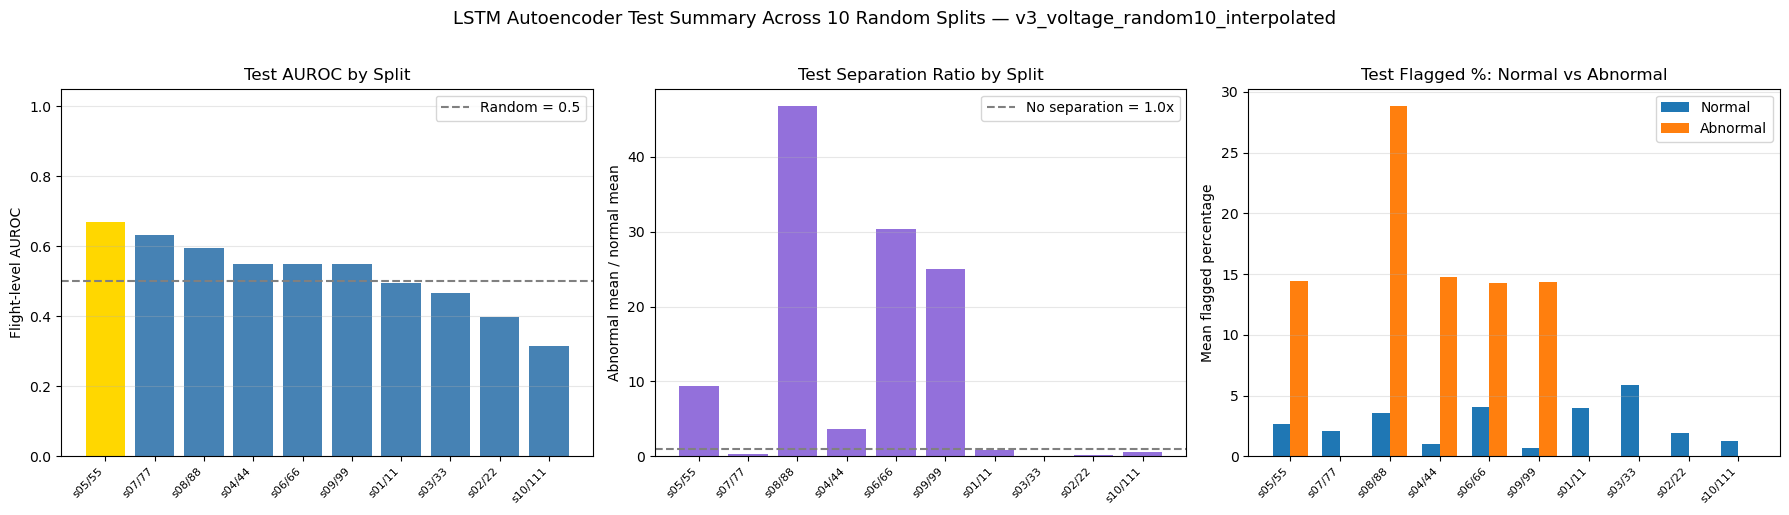

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/cross_split_test_summary_plot_v3_voltage_random10_interpolated.png


In [114]:
# ============================================================
# MASTER CROSS-SPLIT SUMMARY
# ============================================================

all_metrics_df = pd.concat(ALL_METRICS, ignore_index=True)
all_row_summary_df = pd.concat(ALL_ROW_SUMMARIES, ignore_index=True)
all_flight_summary_df = pd.concat(ALL_FLIGHT_SUMMARIES, ignore_index=True)

all_metrics_path = MASTER_OUTPUT_DIR / f"all_split_metrics_{DATA_VERSION}.csv"
all_row_summary_path = MASTER_OUTPUT_DIR / f"all_row_summaries_{DATA_VERSION}.csv"
all_flight_summary_path = MASTER_OUTPUT_DIR / f"all_flight_summaries_{DATA_VERSION}.csv"

all_metrics_df.to_csv(all_metrics_path, index=False)
all_row_summary_df.to_csv(all_row_summary_path, index=False)
all_flight_summary_df.to_csv(all_flight_summary_path, index=False)

print("Saved:", all_metrics_path)
print("Saved:", all_row_summary_path)
print("Saved:", all_flight_summary_path)

# Focus on validation and test only
val_test_metrics = all_metrics_df[
    all_metrics_df["data_split"].isin(["Validation", "Test"])
].copy()

test_metrics = all_metrics_df[
    all_metrics_df["data_split"] == "Test"
].copy()

test_metrics = (
    test_metrics
    .sort_values("flight_auroc", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "="*100)
print("TEST PERFORMANCE ACROSS 10 RANDOM SPLITS")
print("Sorted by flight-level AUROC")
print("="*100)

display(test_metrics)

cross_split_summary_path = MASTER_OUTPUT_DIR / f"cross_split_test_summary_{DATA_VERSION}.csv"
test_metrics.to_csv(cross_split_summary_path, index=False)

print("Saved:", cross_split_summary_path)

# ============================================================
# Best split by test AUROC
# ============================================================

best = test_metrics.iloc[0]

print("\n" + "="*80)
print("BEST TEST SPLIT BY FLIGHT-LEVEL AUROC")
print("="*80)

print(f"Split                    : {best['split']}")
print(f"Flight AUROC             : {best['flight_auroc']:.4f}")
print(f"Flight AUPRC             : {best['flight_auprc']:.4f}")
print(f"Baseline AUPRC           : {best['baseline_auprc']:.4f}")
print(f"Separation ratio         : {best['separation_ratio']:.2f}x")
print(f"Mean flight score normal : {best['mean_flight_score_normal']:.6f}")
print(f"Mean flight score abnorm : {best['mean_flight_score_abnormal']:.6f}")
print(f"Flagged % normal         : {best['mean_flagged_pct_normal']:.2f}%")
print(f"Flagged % abnormal       : {best['mean_flagged_pct_abnormal']:.2f}%")

# ============================================================
# Aggregate statistics
# ============================================================

print("\n" + "="*80)
print("AGGREGATE TEST STATISTICS ACROSS 10 SPLITS")
print("="*80)

cols = [
    "flight_auroc",
    "flight_auprc",
    "baseline_auprc",
    "separation_ratio",
    "mean_flight_score_normal",
    "mean_flight_score_abnormal",
    "mean_flagged_pct_normal",
    "mean_flagged_pct_abnormal"
]

print(test_metrics[cols].describe().round(4).to_string())

# ============================================================
# Cross-split plots
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

split_labels = [
    s.replace("split_", "s").replace("_seed_", "/")
    for s in test_metrics["split"]
]

# AUROC
ax = axes[0]
bar_colors = ["gold" if i == 0 else "steelblue" for i in range(len(test_metrics))]

ax.bar(range(len(test_metrics)), test_metrics["flight_auroc"], color=bar_colors)
ax.axhline(0.5, color="gray", linestyle="--", label="Random = 0.5")

ax.set_xticks(range(len(test_metrics)))
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Flight-level AUROC")
ax.set_title("Test AUROC by Split")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3, axis="y")

# Separation ratio
ax = axes[1]

ax.bar(range(len(test_metrics)), test_metrics["separation_ratio"], color="mediumpurple")
ax.axhline(1.0, color="gray", linestyle="--", label="No separation = 1.0x")

ax.set_xticks(range(len(test_metrics)))
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Abnormal mean / normal mean")
ax.set_title("Test Separation Ratio by Split")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")

# Flagged percentage
ax = axes[2]

x = np.arange(len(test_metrics))
width = 0.35

ax.bar(
    x - width / 2,
    test_metrics["mean_flagged_pct_normal"],
    width,
    label="Normal"
)

ax.bar(
    x + width / 2,
    test_metrics["mean_flagged_pct_abnormal"],
    width,
    label="Abnormal"
)

ax.set_xticks(x)
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Mean flagged percentage")
ax.set_title("Test Flagged %: Normal vs Abnormal")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")

plt.suptitle(
    f"LSTM Autoencoder Test Summary Across 10 Random Splits — {DATA_VERSION}",
    fontsize=13,
    y=1.02
)

plt.tight_layout()

summary_plot_path = MASTER_OUTPUT_DIR / f"cross_split_test_summary_plot_{DATA_VERSION}.png"

plt.savefig(summary_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", summary_plot_path)

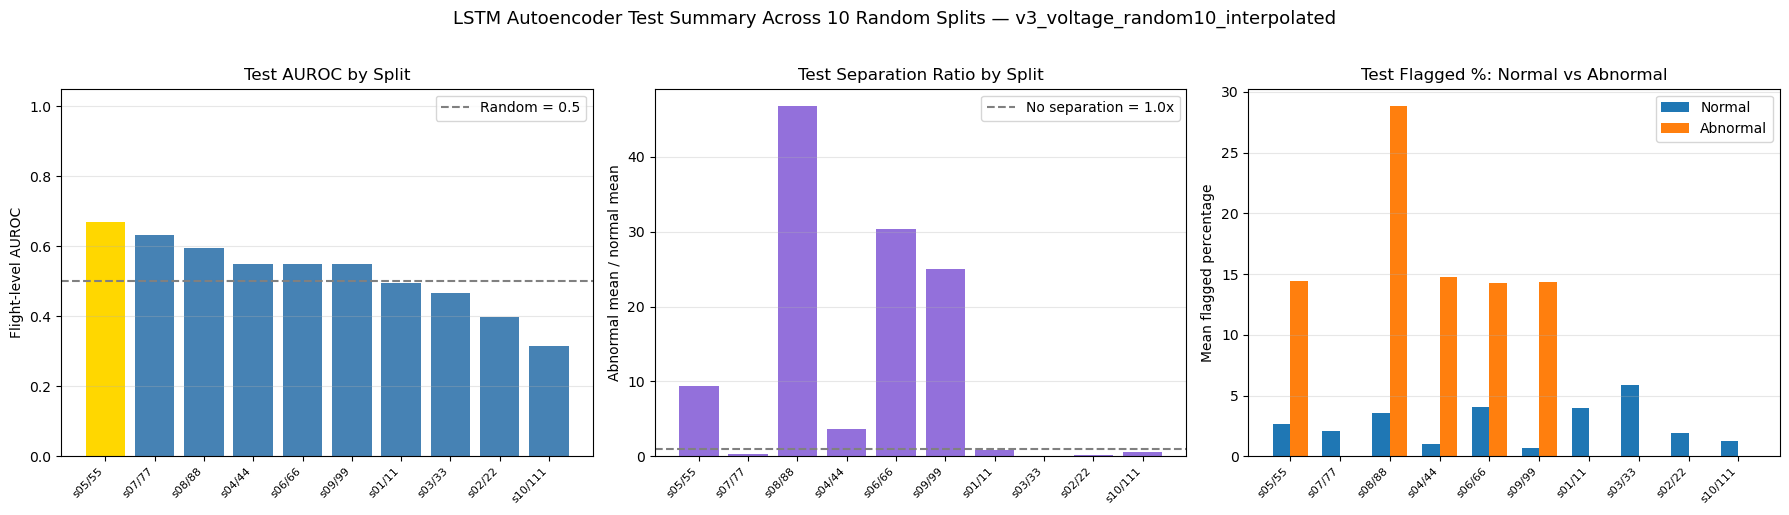

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/cross_split_test_summary_plot_v3_voltage_random10_interpolated.png


In [ ]:
# ============================================================
# Cross-split plots — stacked vertical layout
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 16))

split_labels = [
    s.replace("split_", "s").replace("_seed_", "/")
    for s in test_metrics["split"]
]

auroc_vals = test_metrics["flight_auroc"].tolist()
sep_vals   = test_metrics["separation_ratio"].tolist()
flag_nor   = test_metrics["mean_flagged_pct_normal"].tolist()
flag_abn   = test_metrics["mean_flagged_pct_abnormal"].tolist()
mean_auroc = np.mean(auroc_vals)

x = np.arange(len(test_metrics))

# ── Plot 1: AUROC ──────────────────────────────────────────
ax = axes[0]

bar_colors = []
for i, a in enumerate(auroc_vals):
    if i == 0:
        bar_colors.append("gold")
    elif a >= 0.5:
        bar_colors.append("#2196F3")
    else:
        bar_colors.append("#EF5350")

bars = ax.bar(x, auroc_vals, color=bar_colors, width=0.6, edgecolor="white")

ax.axhline(0.5, color="black", linestyle="--", linewidth=1.2,
           label="Random chance (AUROC = 0.50)")
ax.axhline(mean_auroc, color="orange", linestyle="-.", linewidth=1.2,
           label=f"Mean AUROC = {mean_auroc:.3f}")

for bar, val in zip(bars, auroc_vals):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01,
            f"{val:.3f}", ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Flight-level AUROC", fontsize=10)
ax.set_ylim(0, 0.88)
ax.set_title(
    "Plot 1: Flight-Level AUROC per Split\n"
    "Blue = above random chance  |  Red = below random chance  |  Gold = best split",
    fontsize=10
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

# ── Plot 2: Flagged % ──────────────────────────────────────
ax = axes[1]

width = 0.35
bars_abn = ax.bar(x - width / 2, flag_abn, width,
                  color="#EF5350", label="Abnormal flights", edgecolor="white")
bars_nor = ax.bar(x + width / 2, flag_nor, width,
                  color="#90CAF9", label="Normal flights", edgecolor="white")

for bar in bars_abn:
    h = bar.get_height()
    if h > 0.5:
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.3,
                f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5,
                color="#C62828")

for bar in bars_nor:
    h = bar.get_height()
    if h > 0.5:
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.3,
                f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5,
                color="#1565C0")

ax.set_xticks(x)
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("% of rows flagged as anomalous", fontsize=10)
ax.set_title(
    "Plot 2: Percentage of Rows Flagged as Anomalous — Normal vs Abnormal Flights\n"
    "A good model flags more abnormal rows (red) than normal rows (blue)",
    fontsize=10
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

# ── Plot 3: Separation ratio ───────────────────────────────
ax = axes[2]

sep_colors = ["#43A047" if s >= 1.0 else "#EF5350" for s in sep_vals]
sep_capped = [min(s, 15) for s in sep_vals]
sep_labels = [f"{s:.1f}×" if s <= 15 else f"{s:.1f}×*" for s in sep_vals]

bars3 = ax.bar(x, sep_capped, color=sep_colors, width=0.6, edgecolor="white")

ax.axhline(1.0, color="black", linestyle="--", linewidth=1.2,
           label="No separation (ratio = 1.0)")

for bar, label in zip(bars3, sep_labels):
    ax.text(bar.get_x() + bar.get_width() / 2,
            min(bar.get_height(), 14.3) + 0.15,
            label, ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Separation ratio (capped at 15×)", fontsize=10)
ax.set_title(
    "Plot 3: Anomaly Score Separation Ratio — Abnormal Mean ÷ Normal Mean\n"
    "Green = abnormal flights score higher (good)  |  Red = normal flights score higher (inverted)",
    fontsize=10
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

ax.text(0.99, 0.97,
        "* capped at 15× for display; actual value shown as label",
        transform=ax.transAxes, fontsize=7.5, ha="right", va="top",
        color="gray", style="italic")

# ── Title and save ─────────────────────────────────────────
plt.suptitle(
    f"LSTM Autoencoder Anomaly Detection — Summary Across 10 Random Splits\n({DATA_VERSION})",
    fontsize=13, fontweight="bold", y=1.01
)

plt.tight_layout()

summary_plot_path = MASTER_OUTPUT_DIR / f"cross_split_test_summary_plot_{DATA_VERSION}.png"
plt.savefig(summary_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", summary_plot_path)

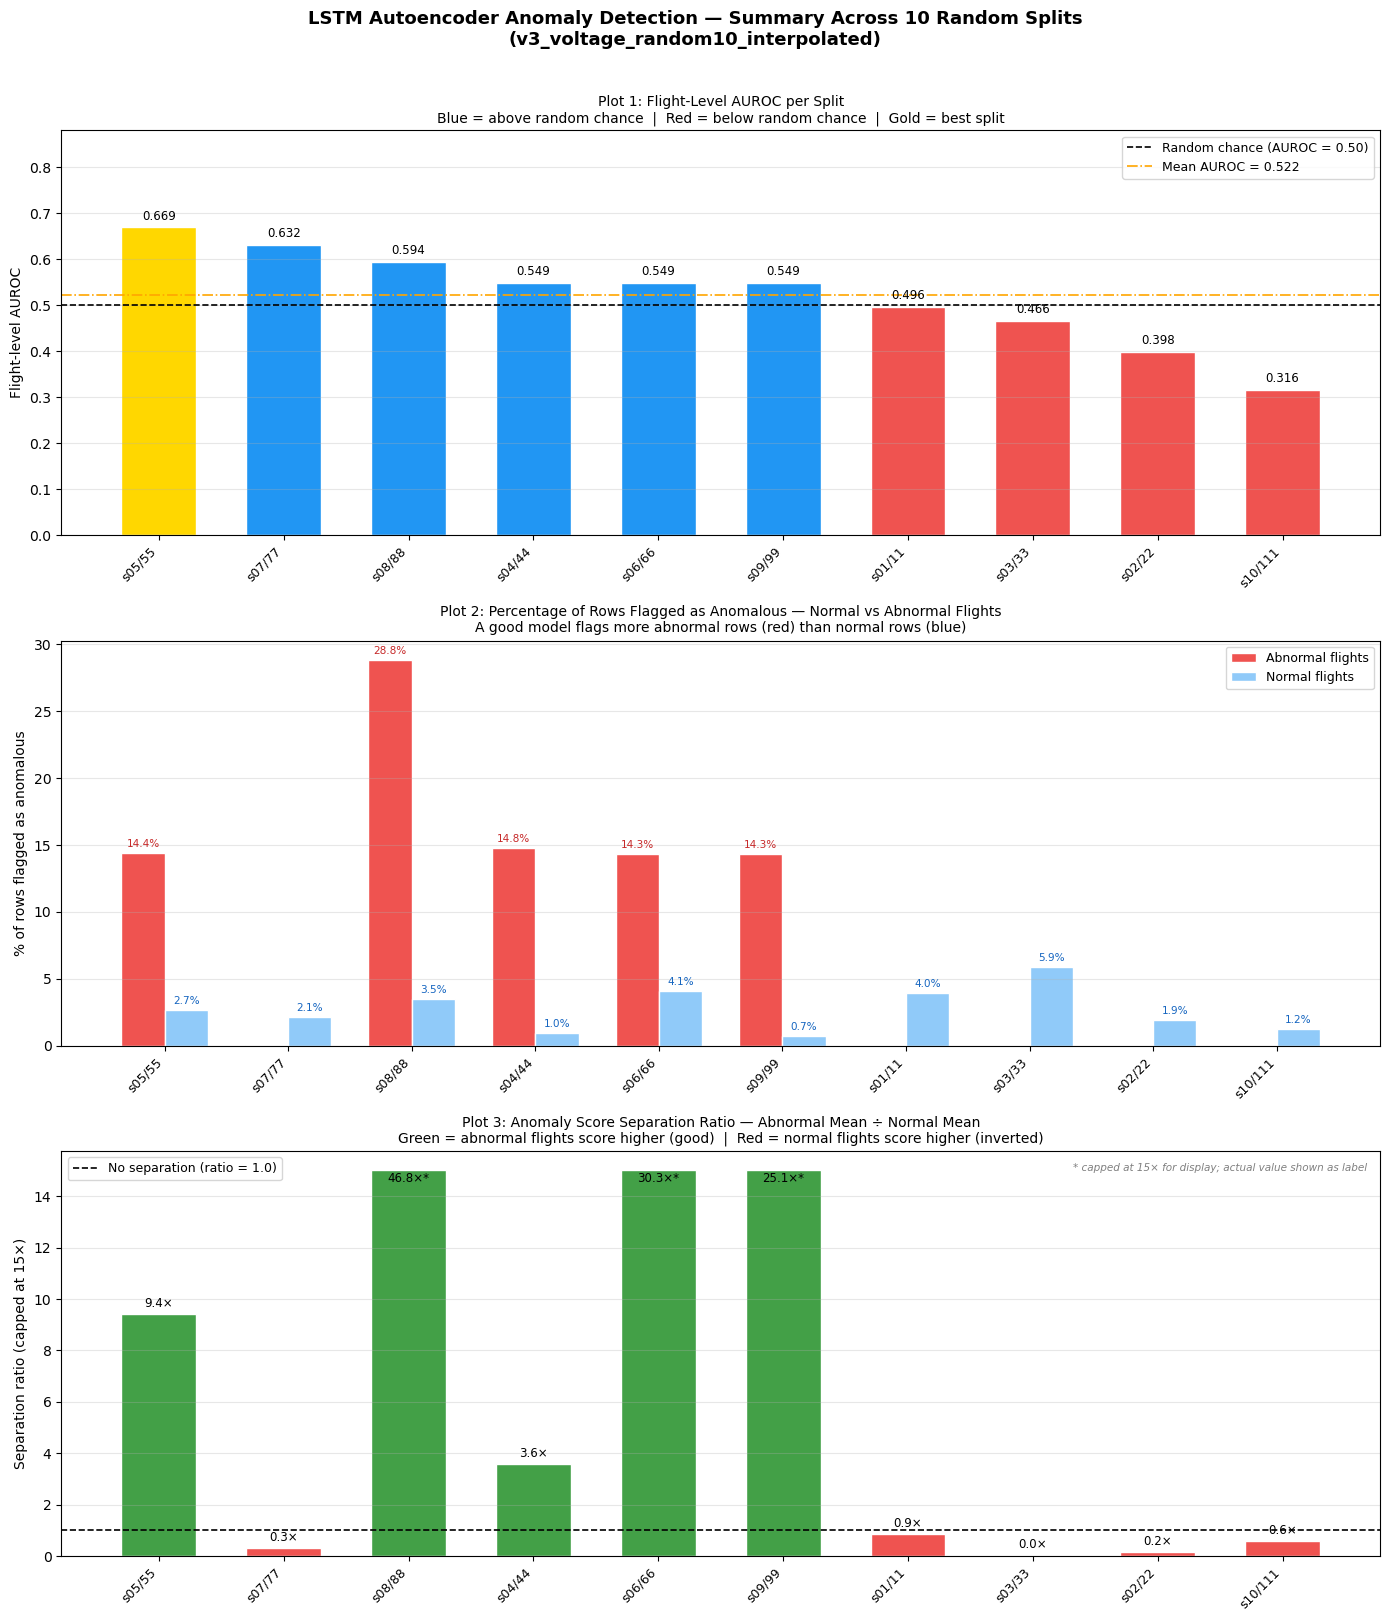

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic/cross_split_test_summary_plot_v3_voltage_random10_interpolated.png


In [117]:
# ============================================================
# Cross-split plots — stacked vertical layout
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 16))

split_labels = [
    s.replace("split_", "s").replace("_seed_", "/")
    for s in test_metrics["split"]
]

auroc_vals = test_metrics["flight_auroc"].tolist()
sep_vals   = test_metrics["separation_ratio"].tolist()
flag_nor   = test_metrics["mean_flagged_pct_normal"].tolist()
flag_abn   = test_metrics["mean_flagged_pct_abnormal"].tolist()
mean_auroc = np.mean(auroc_vals)

x = np.arange(len(test_metrics))

# ── Plot 1: AUROC ──────────────────────────────────────────
ax = axes[0]

bar_colors = []
for i, a in enumerate(auroc_vals):
    if i == 0:
        bar_colors.append("gold")
    elif a >= 0.5:
        bar_colors.append("#2196F3")
    else:
        bar_colors.append("#EF5350")

bars = ax.bar(x, auroc_vals, color=bar_colors, width=0.6, edgecolor="white")

ax.axhline(0.5, color="black", linestyle="--", linewidth=1.2,
           label="Random chance (AUROC = 0.50)")
ax.axhline(mean_auroc, color="orange", linestyle="-.", linewidth=1.2,
           label=f"Mean AUROC = {mean_auroc:.3f}")

for bar, val in zip(bars, auroc_vals):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01,
            f"{val:.3f}", ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Flight-level AUROC", fontsize=10)
ax.set_ylim(0, 0.88)
ax.set_title(
    "Plot 1: Flight-Level AUROC per Split\n"
    "Blue = above random chance  |  Red = below random chance  |  Gold = best split",
    fontsize=10
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

# ── Plot 2: Flagged % ──────────────────────────────────────
ax = axes[1]

width = 0.35
bars_abn = ax.bar(x - width / 2, flag_abn, width,
                  color="#EF5350", label="Abnormal flights", edgecolor="white")
bars_nor = ax.bar(x + width / 2, flag_nor, width,
                  color="#90CAF9", label="Normal flights", edgecolor="white")

for bar in bars_abn:
    h = bar.get_height()
    if h > 0.5:
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.3,
                f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5,
                color="#C62828")

for bar in bars_nor:
    h = bar.get_height()
    if h > 0.5:
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.3,
                f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5,
                color="#1565C0")

ax.set_xticks(x)
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("% of rows flagged as anomalous", fontsize=10)
ax.set_title(
    "Plot 2: Percentage of Rows Flagged as Anomalous — Normal vs Abnormal Flights\n"
    "A good model flags more abnormal rows (red) than normal rows (blue)",
    fontsize=10
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

# ── Plot 3: Separation ratio ───────────────────────────────
ax = axes[2]

sep_colors = ["#43A047" if s >= 1.0 else "#EF5350" for s in sep_vals]
sep_capped = [min(s, 15) for s in sep_vals]
sep_labels = [f"{s:.1f}×" if s <= 15 else f"{s:.1f}×*" for s in sep_vals]

bars3 = ax.bar(x, sep_capped, color=sep_colors, width=0.6, edgecolor="white")

ax.axhline(1.0, color="black", linestyle="--", linewidth=1.2,
           label="No separation (ratio = 1.0)")

for bar, label in zip(bars3, sep_labels):
    ax.text(bar.get_x() + bar.get_width() / 2,
            min(bar.get_height(), 14.3) + 0.15,
            label, ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(split_labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Separation ratio (capped at 15×)", fontsize=10)
ax.set_title(
    "Plot 3: Anomaly Score Separation Ratio — Abnormal Mean ÷ Normal Mean\n"
    "Green = abnormal flights score higher (good)  |  Red = normal flights score higher (inverted)",
    fontsize=10
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")

ax.text(0.99, 0.97,
        "* capped at 15× for display; actual value shown as label",
        transform=ax.transAxes, fontsize=7.5, ha="right", va="top",
        color="gray", style="italic")

# ── Title and save ─────────────────────────────────────────
plt.suptitle(
    f"LSTM Autoencoder Anomaly Detection — Summary Across 10 Random Splits\n({DATA_VERSION})",
    fontsize=13, fontweight="bold", y=1.01
)

plt.tight_layout()

summary_plot_path = MASTER_OUTPUT_DIR / f"cross_split_test_summary_plot_{DATA_VERSION}.png"
plt.savefig(summary_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", summary_plot_path)